# TP Ciencia de Datos — Predicción del puntaje de reseñas de Letterboxd

**Ciencia de Datos · 2do Cuatrimestre 2026**

**Integrantes:** _(completar)_

---

## Objetivo

Queremos predecir el puntaje (`Rating`, de 0.5 a 5 estrellas, de a media estrella) que un usuario le pone a una película a partir del texto de su reseña.

En cada etapa vamos a plantear las alternativas posibles, probarlas cuando se pueda, y dejar escrita la decisión que tomamos y por qué (en los bloques **✅ Decisión**).

Seguimos las etapas del proceso de ciencia de datos que vimos en clase (CRISP-DM): entender los datos → prepararlos → modelar → evaluar.

## Índice
1. Carga de datos
2. Análisis del target (`Rating`)
3. Análisis exploratorio general
4. Análisis de `Movie`, `Date` y `Status`
5. Limpieza
6. División train / validación / test
7. Preprocesamiento del texto
8. Ingeniería de features
9. Modelado: clasificación vs. regresión
10. Evaluación final en test
11. Completar las reseñas sin puntaje
12. Conclusiones
13. Uso de IA generativa

## 0. Librerías y configuración

Necesita el archivo `letterboxd_250movie_reviews.csv` en la misma carpeta. Si falta alguna librería: `pip install nltk emoji seaborn`.

Tarda unos 10–15 minutos en correr completo (depende de la computadora).

In [ ]:
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from scipy.sparse import hstack, csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error, f1_score, confusion_matrix
from nltk.stem import SnowballStemmer

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 150)

SEED = 42
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})

## 1. Carga de datos

In [ ]:
df = pd.read_csv('letterboxd_250movie_reviews.csv')
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (90016, 6)


,Unnamed: 0,Review,Rating,Date,Status,Movie
0,0,"I am an idiot. Why is it that I still dread watching ""classics""? I'm talking about those foreign, black and white movies that are whispered about ...",★★★★★,01 Dec 2013,Watched,harakiri
1,1,honor in the individual is virtue honor in a society is madness,★★★★★,18 Jan 2022,NaN,harakiri
2,2,"Brilliant. Riveting exploration of mortality and honor. Timeless, impeccable, and hypnotic. I find myself looking forward to future viewings, and ...",NaN,26 Jan 2024,Watched,harakiri
3,3,"God damn what an impeccable film. Not dated in the least, if you tried to tell this same story now, 60 years later, this would still be the best w...",★★★★★,21 Jun 2021,Watched,harakiri
4,4,"95First thing's first: giving a big thanks to Mitchell, one of my awesome Patrons, for finally forcing me to watch this fucking movie. Every so of...",★★★★★,06 Sep 2020,Watched,harakiri


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90016 entries, 0 to 90015
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  90016 non-null  int64
 1   Review      90011 non-null  str  
 2   Rating      86513 non-null  str  
 3   Date        90016 non-null  str  
 4   Status      86858 non-null  str  
 5   Movie       90016 non-null  str  
dtypes: int64(1), str(5)
memory usage: 4.1 MB


- `Unnamed: 0` es el índice que se guardó al exportar el CSV, no es información → la borramos.
- Todas las columnas son texto. `Rating` viene como estrellas (`★★★★½`) y `Date` como texto (`01 Dec 2013`), así que hay que convertirlas.

In [ ]:
df = df.drop(columns='Unnamed: 0')
print('Cantidad de reseñas:', len(df))
print('Cantidad de películas distintas:', df['Movie'].nunique())
print('\nValores faltantes:')
print(df.isna().sum())

Cantidad de reseñas: 90016
Cantidad de películas distintas: 250

Valores faltantes:
Review       5
Rating    3503
Date         0
Status    3158
Movie        0
dtype: int64


## 2. Análisis del target: `Rating`

In [ ]:
df['Rating'].value_counts(dropna=False)

Rating
★★★★★    41077
★★★★½    21031
★★★★     15031
★★★½      4411
NaN       3503
★★★       2380
★★½        892
★★         737
½          340
★          320
★½         294
Name: count, dtype: int64

Cada `★` vale 1 y `½` vale 0.5. Convertimos el texto a número contando los caracteres:

In [ ]:
def estrellas_a_numero(s):
    if pd.isna(s):
        return np.nan
    return s.count('★') + 0.5 * s.count('½')

df['y'] = df['Rating'].map(estrellas_a_numero)

conteo = df['y'].value_counts().sort_index()
porcentaje = (100 * conteo / conteo.sum()).round(2)
print('Clases distintas:', df['y'].nunique())
pd.DataFrame({'reseñas': conteo, '%': porcentaje})

Clases distintas: 10


,reseñas,%
y,,
0.5,340,0.39
1.0,320,0.37
1.5,294,0.34
2.0,737,0.85
2.5,892,1.03
3.0,2380,2.75
3.5,4411,5.10
4.0,15031,17.37
4.5,21031,24.31


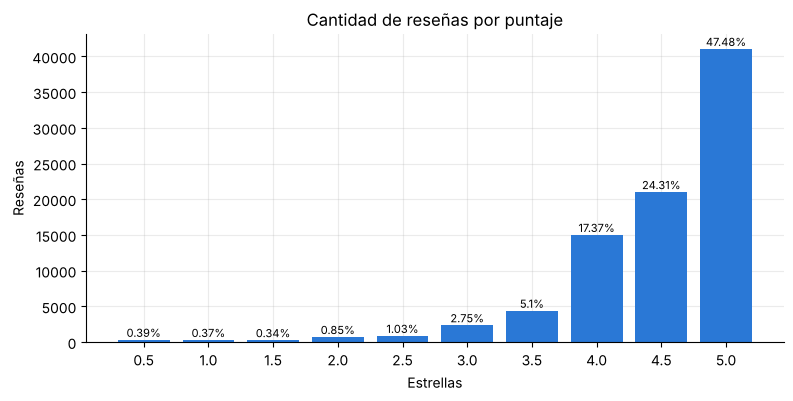

Media: 4.48 | Mediana: 4.5 | Moda: 5.0
% de reseñas con 4 estrellas o más: 85.7


In [ ]:
fig, ax = plt.subplots()
ax.bar(conteo.index.astype(str), conteo.values, color=AZUL)
for i, p in enumerate(porcentaje):
    ax.text(i, conteo.values[i] + 400, f'{p}%', ha='center', fontsize=8)
ax.set_title('Cantidad de reseñas por puntaje')
ax.set_xlabel('Estrellas'); ax.set_ylabel('Reseñas')
plt.show()

print('Media:', round(df['y'].mean(), 2), '| Mediana:', df['y'].median(), '| Moda:', df['y'].mode()[0])
print('% de reseñas con 4 estrellas o más:', round(100 * (df['y'] >= 4).mean(), 1))

**Lo que vemos:**
- Hay **10 clases** (0.5, 1, 1.5, … , 5). Es una variable **ordinal**: tiene orden, 4.5 está más cerca de 5 que de 1.
- El dataset está **muy desbalanceado**: casi la mitad de las reseñas son de 5★ y ~86% tienen 4★ o más. Tiene sentido porque son las 250 películas mejor puntuadas de Letterboxd.
- Las **medias estrellas se usan igual que las enteras**: 4.5★ es la segunda clase más frecuente y 3.5★ tiene más reseñas que 3★.

**¿Cómo afecta esto?**
- Un modelo que **siempre dice 5★ acierta el 47%** sin aprender nada. El accuracy va a estar inflado (accuracy paradox, clase 5).
- Las clases bajas (0.5★ a 2.5★) tienen muy pocos ejemplos, así que probablemente al modelo le cueste predecirlas.
- Equivocarse por media estrella (4.5 en vez de 5) no es tan grave como equivocarse por 4 estrellas, pero el accuracy cuenta los dos errores igual. Por eso vamos a usar también MAE (sección 9).

### Reseñas sin puntaje

In [ ]:
print('Reseñas sin puntaje:', df['y'].isna().sum())

Reseñas sin puntaje: 3503


Opciones que vimos en clase para valores faltantes: eliminar las filas, rellenar con un valor (media, moda) o predecirlo con un modelo.

**✅ Decisión:** no las usamos para entrenar. Rellenarlas con la media o la moda sería inventar el target. Pero tampoco las tiramos: las separamos y al final usamos nuestro modelo para **predecirles el puntaje**, que es justamente uno de los usos que plantea el enunciado.

## 3. Análisis exploratorio general

### 3.1 Duplicados

In [ ]:
print('Filas duplicadas exactas:', df.duplicated().sum())
print('Reseñas con el mismo texto:', df['Review'].duplicated().sum())
print('\nTextos más repetidos:')
df.loc[df['Review'].duplicated(keep=False), 'Review'].value_counts().head(8)

Filas duplicadas exactas: 4


Reseñas con el mismo texto: 216

Textos más repetidos:


Review
Great           15
Masterpiece.     8
Wow              7
Masterpiece      7
Beautiful.       7
Perfection.      6
MASTERPIECE      6
100/100          5
Name: count, dtype: int64

Solo hay **4 filas duplicadas exactas** (todas las columnas iguales): son errores al juntar los datos y las borramos.

Los textos repetidos son casi todos reseñas cortas como "Great" o "Masterpiece.", escritas por **distintos usuarios** (tienen distinta fecha y puntaje). Esas no son duplicados, así que las dejamos.

### 3.2 Longitud de las reseñas

In [ ]:
texto = df['Review'].fillna('')
palabras = texto.str.split().str.len()
print('Reseñas vacías:', df['Review'].isna().sum())
print('Reseñas de una sola palabra:', (palabras == 1).sum())
palabras.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1)

Reseñas vacías: 5
Reseñas de una sola palabra: 605


count    90016.0
mean       173.0
std        284.8
min          0.0
5%           6.0
25%         23.0
50%         82.0
75%        216.0
95%        624.0
99%       1201.0
max      14783.0
Name: Review, dtype: float64

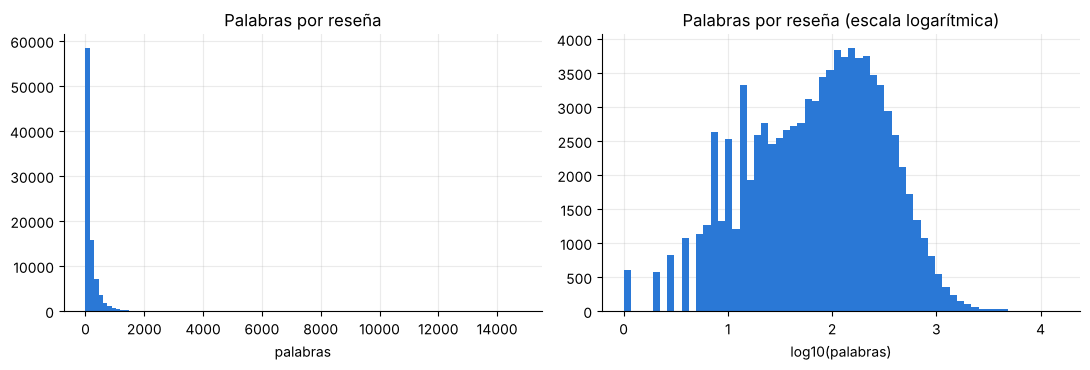

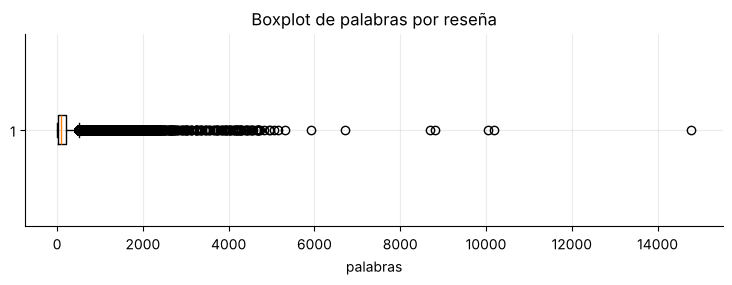

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(palabras, bins=100, color=AZUL)
axes[0].set_title('Palabras por reseña'); axes[0].set_xlabel('palabras')
axes[1].hist(np.log10(palabras[palabras > 0]), bins=60, color=AZUL)
axes[1].set_title('Palabras por reseña (escala logarítmica)'); axes[1].set_xlabel('log10(palabras)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.boxplot(palabras, vert=False)
ax.set_title('Boxplot de palabras por reseña'); ax.set_xlabel('palabras')
plt.show()

- La mediana es de unas 80 palabras, pero hay reseñas larguísimas (la más larga tiene casi 15.000). La distribución tiene una **cola larga a la derecha**.
- En el boxplot aparecen muchísimos "outliers", pero en escala logarítmica la distribución se ve bastante normal. No son errores, son reseñas reales que son largas.

**✅ Decisión:** **no borramos** reseñas por ser largas o cortas. Las cortas ("Masterpiece.") dicen mucho del puntaje. Las largas tienen más texto para aprender. Solo borramos las **5 vacías**, porque no hay nada de qué predecir. Si usamos la longitud como feature, le aplicamos logaritmo por la cola larga.

### 3.3 Otras cosas que encontramos en el texto

In [ ]:
print('Reseñas cortadas que terminan en "… more":', texto.str.contains(r'…\s*more$').sum())

cant_emojis = texto.map(emoji.emoji_count)
print('Reseñas con emojis:', (cant_emojis > 0).sum(), f'({100 * (cant_emojis > 0).mean():.1f}%)')

# Idioma: contamos qué proporción de las palabras son stopwords del inglés.
# Si casi ninguna lo es, probablemente la reseña está en otro idioma.
def es_ingles(t):
    ws = re.findall(r'[^\W\d_]+', t.lower())
    if len(ws) < 5:
        return 'muy corta'
    prop = sum(w in ENGLISH_STOP_WORDS for w in ws) / len(ws)
    return 'inglés' if prop >= 0.12 else 'otro idioma'

df['idioma'] = texto.map(es_ingles)
print('\n', df['idioma'].value_counts())
print('\nEjemplos de "otro idioma":')
for t in df.loc[df['idioma'] == 'otro idioma', 'Review'].sample(6, random_state=1):
    print('  -', t[:100])

Reseñas cortadas que terminan en "… more": 43


Reseñas con emojis: 5991 (6.7%)



 idioma
inglés         80535
otro idioma     6468
muy corta       3013
Name: count, dtype: int64

Ejemplos de "otro idioma":
  - Quanto amor envolvido em um só filme, Kore-eda transforma o banal em algo extraordinário, o caminho 
  - "Você não me conhece, mas eu conheço você"Um drama histórico e político. Praticamente um "baseado em
  - La película (o mini serie que fue la que vi) definitiva sobre las relaciones de pareja. El amor y de
  - Über die besten ersten (!!) 20 Minuten in der Filmgeschichte - aus meinem Video zum Tod von Ennio Mo
  - Endlich! ❤️ Le Samouraï  besetzte seit Jahren den obersten Platz meiner Watchlist, was vor allem ein
  - amansız hastalığa yakalanan bir şairin son gününü anlatıyor film. ama ne anlatmak... uzun uzun planl


- **43 reseñas están cortadas** y terminan en "… more" (el scraper guardó solo el principio). Le sacamos ese "… more" porque no es parte de la opinión.
- Un ~7% de las reseñas tiene **emojis**. Pueden decir mucho del sentimiento (😭, 🔥, 💔), así que no los vamos a borrar (ver sección 7).
- Un ~7% de las reseñas **está en otro idioma** (portugués, español, alemán, árabe, turco…). Lo detectamos con un método simple: ver qué proporción de las palabras son stopwords en inglés. Mirando los ejemplos, funciona bastante bien.

**✅ Decisión sobre otros idiomas:** las dejamos. Son pocas, y en la plataforma real también van a llegar reseñas en otros idiomas. Al final vamos a medir aparte cómo le va al modelo con ellas.

## 4. Análisis de `Movie`, `Date` y `Status`

### 4.1 `Movie`

count    250.0
mean     346.1
std        8.2
min      260.0
25%      343.0
50%      347.0
75%      351.0
max      359.0
Name: count, dtype: float64


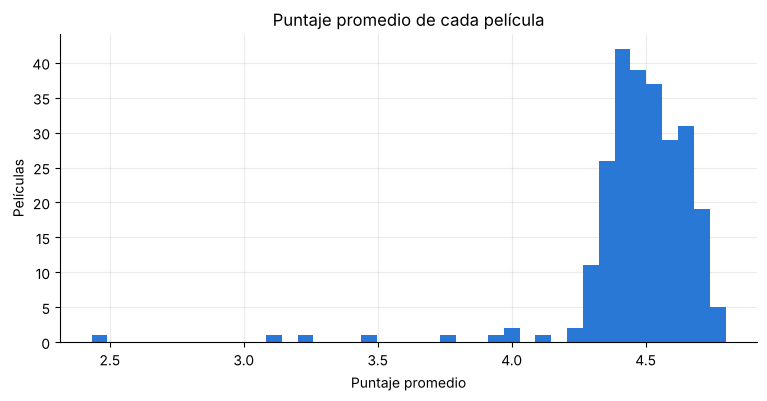

Películas con menor promedio:


,mean,count
Movie,,
parasite,2.43,344
war-and-peace,3.11,335
heat,3.24,330
eureka,3.46,331
monster,3.78,349


In [ ]:
por_peli = df.groupby('Movie')['y'].agg(['mean', 'count'])
print(por_peli['count'].describe().round(1))

fig, ax = plt.subplots()
ax.hist(por_peli['mean'], bins=40, color=AZUL)
ax.set_title('Puntaje promedio de cada película'); ax.set_xlabel('Puntaje promedio'); ax.set_ylabel('Películas')
plt.show()
print('Películas con menor promedio:')
por_peli.sort_values('mean').head(5).round(2)

In [ ]:
# ¿Por qué "parasite" tiene promedio 2.4 si la de Bong Joon-ho es de las mejores?
for t in df.loc[df['Movie'] == 'parasite', 'Review'].head(3):
    print('-', t[:150])

- Hear me out!Charles Band’s Parasite was released in 1982, 37 years before Bong Joon-ho’s Parasite. In 2006 Charles Band directed Evil Bong, just a yea
- I’m not sure why so many people are calling this the best movie of 2019, but hey, to each their own.
- A post-apocalyptic movie directed by Charles Band, starring a young Demi Moore and a large, killer parasite? Yes, please!


- Hay unas **360 reseñas por película**, así que en ese sentido está balanceado.
- La mayoría de las películas tiene un promedio entre 4.4 y 4.6, salvo algunas pocas que dan bastante menos.
- **Hallazgo:** `parasite` no es la película de 2019 sino *Parasite* de **1982**, una de terror de bajo presupuesto. Lo mismo pasa con `heat` (es una de Burt Reynolds, no la de Al Pacino). Al juntar los datos se confundieron películas con el mismo nombre. No afecta mucho a nuestro modelo, porque predecimos a partir del texto de la reseña, pero es un error de calidad de datos a tener en cuenta.

**¿Usamos la película como feature?**
- A favor: algunas películas tienen promedios distintos y eso podría ayudar.
- En contra: si llega una reseña de una película que no está en el dataset, el modelo no tendría esa información. Queremos un modelo que funcione para **cualquier** película.

**✅ Decisión:** **no usamos `Movie`** como feature.

### 4.2 `Date`

In [ ]:
df['fecha'] = pd.to_datetime(df['Date'], format='%d %b %Y')
print('Fecha mínima:', df['fecha'].min().date(), '| Fecha máxima:', df['fecha'].max().date())
anio = df['fecha'].dt.year
print('\nAños raros:')
print(anio[(anio < 2011) | (anio > 2024)].value_counts().sort_index())

Fecha mínima: 0004-06-19 | Fecha máxima: 2566-08-17

Años raros:
fecha
4        1
1896     1
1931     1
1948     1
1951     3
1952     4
1953     1
1955     3
1957     6
1958     1
1959     5
1960     1
1961     1
1962     1
1963     3
1964     1
1965     1
1966     3
1968     1
1970     2
1971     1
1974     1
1976     2
1977     1
1978     1
1981     3
1983     2
1985     2
1987     1
1992     1
1993     2
1994     9
1995     6
1996     2
1997     4
1998     6
1999     7
2000     6
2001     9
2002     8
2003     5
2004    18
2005    14
2006    16
2007    19
2008    15
2009     6
2010    21
2562     1
2565     1
2566     2
Name: count, dtype: int64


Hay años imposibles: el **año 4** y años **2562–2566**. Investigando, 2566 es el año 2023 en el **calendario budista** (que usa Tailandia: hay que restar 543). Letterboxd existe desde 2011, y las fechas anteriores son fechas que el usuario carga a mano (o errores de tipeo).

**✅ Decisión:** corregimos los años budistas (restando 543) y, para usar el año, lo limitamos al rango 2011–2024. No borramos esas reseñas porque el texto está bien.

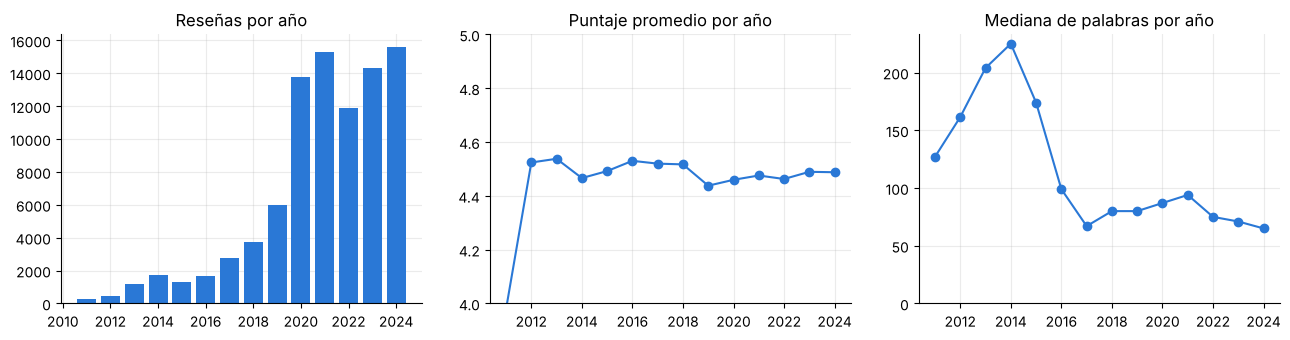

,reseñas,puntaje_medio,palabras_mediana
anio,,,
2011,271,3.98,127.0
2012,438,4.52,161.5
2013,1183,4.54,204.0
2014,1715,4.47,225.0
2015,1335,4.49,174.0
2016,1666,4.53,99.0
2017,2750,4.52,67.0
2018,3736,4.52,80.0
2019,6001,4.44,80.0


In [ ]:
df['anio'] = np.where(anio > 2500, anio - 543, anio)
df['anio'] = df['anio'].clip(2011, 2024)

por_anio = df.groupby('anio').agg(reseñas=('y', 'size'), puntaje_medio=('y', 'mean'),
                                  palabras_mediana=('Review', lambda s: s.fillna('').str.split().str.len().median()))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].bar(por_anio.index, por_anio['reseñas'], color=AZUL); axes[0].set_title('Reseñas por año')
axes[1].plot(por_anio.index, por_anio['puntaje_medio'], marker='o', color=AZUL); axes[1].set_ylim(4, 5)
axes[1].set_title('Puntaje promedio por año')
axes[2].plot(por_anio.index, por_anio['palabras_mediana'], marker='o', color=AZUL); axes[2].set_ylim(0, None)
axes[2].set_title('Mediana de palabras por año')
plt.tight_layout(); plt.show()
por_anio.round(2)

- La mayoría de las reseñas son de 2020 en adelante.
- El **puntaje promedio casi no cambia** con los años (siempre ronda 4.5).
- La **longitud** sí cambia: en los años más recientes las reseñas son más cortas.

Conclusión: la fecha no parece ayudar a predecir el puntaje. Lo comprobamos en la sección 8.

### 4.3 `Status`

             count   mean
Status                   
Desconocido   2978  4.366
Rewatched    22437  4.759
Watched      61098  4.379


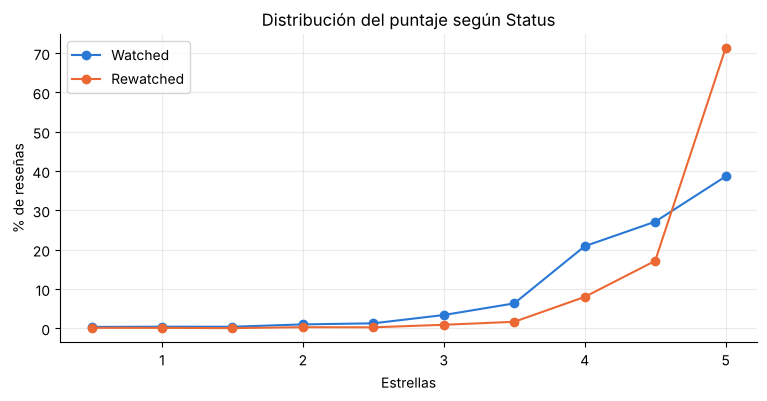

In [ ]:
df['Status'] = df['Status'].fillna('Desconocido')
print(df.groupby('Status')['y'].agg(['count', 'mean']).round(3))

tabla_status = pd.crosstab(df['Status'], df['y'], normalize='index') * 100
fig, ax = plt.subplots()
ax.plot(tabla_status.columns, tabla_status.loc['Watched'], marker='o', color=AZUL, label='Watched')
ax.plot(tabla_status.columns, tabla_status.loc['Rewatched'], marker='o', color=NARANJA, label='Rewatched')
ax.set_title('Distribución del puntaje según Status'); ax.set_xlabel('Estrellas'); ax.set_ylabel('% de reseñas')
ax.legend(); plt.show()

- `Status` dice si el usuario vio la película por primera vez (**Watched**) o si la **volvió a ver** (**Rewatched**). Hay ~3.200 sin dato, que pusimos como "Desconocido".
- Las reseñas *Rewatched* tienen un promedio de **4.76** contra **4.38** de las *Watched*. Tiene sentido: uno vuelve a ver las películas que le gustaron.
- ¿Podría ser "trampa" (data leakage)? No: el usuario marca si es un re-visionado cuando escribe la reseña. No sale del puntaje.

**✅ Decisión:** usamos `Status` como feature, con **one-hot encoding** (clase 3), dejando "Desconocido" como una categoría más.

### 4.4 ¿La longitud tiene que ver con el puntaje?

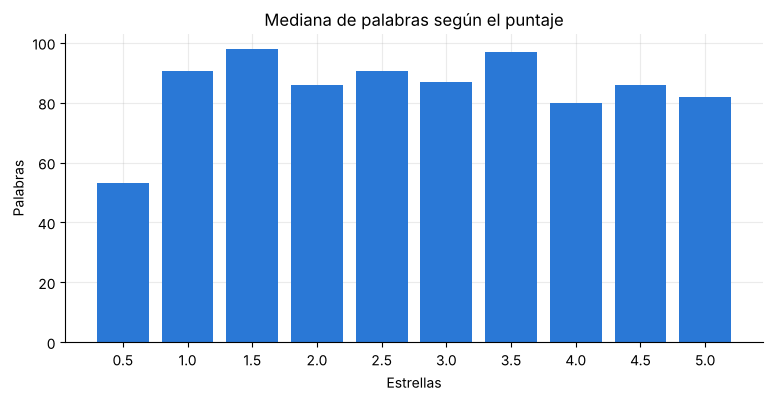

In [ ]:
largo_por_puntaje = df.dropna(subset=['y']).assign(palabras=palabras).groupby('y')['palabras'].median()
fig, ax = plt.subplots()
ax.bar(largo_por_puntaje.index.astype(str), largo_por_puntaje.values, color=AZUL)
ax.set_title('Mediana de palabras según el puntaje'); ax.set_xlabel('Estrellas'); ax.set_ylabel('Palabras')
plt.show()

Las reseñas de 0.5★ son algo más cortas, pero en el resto la longitud es parecida. La longitud sola no parece decir mucho del puntaje.

## 5. Limpieza

Resumen de lo que decidimos en el análisis:

| Problema | Qué hacemos |
|---|---|
| Columna `Unnamed: 0` | Ya la borramos |
| Reseñas sin puntaje | Las separamos para predecirlas al final |
| 4 filas duplicadas exactas | Las borramos |
| 5 reseñas vacías | Las borramos |
| Reseñas cortadas con "… more" | Le sacamos el "… more" |
| Años imposibles | Corregidos (ya lo hicimos) |
| `Status` vacío | Categoría "Desconocido" (ya lo hicimos) |
| Reseñas muy largas y en otros idiomas | Las dejamos |

In [ ]:
df = df.drop_duplicates(subset=['Review', 'Rating', 'Date', 'Status', 'Movie'])
df = df[df['Review'].notna()].copy()
df['Review'] = df['Review'].str.replace(r'…\s*more$', '', regex=True)

sin_puntaje = df[df['y'].isna()].reset_index(drop=True)
data = df[df['y'].notna()].reset_index(drop=True)
print('Reseñas para entrenar y evaluar:', len(data))
print('Reseñas sin puntaje (para el final):', len(sin_puntaje))

Reseñas para entrenar y evaluar: 86504
Reseñas sin puntaje (para el final): 3503


## 6. División train / validación / test

El enunciado plantea tres formas de separar los datos. Cada una mide algo distinto:

- **Aleatoria:** mide qué tan bien predice reseñas nuevas de **las mismas películas**.
- **Temporal** (entrenar con las reseñas viejas, probar con las nuevas): mide qué tan bien funcionaría **en el futuro**, si la forma de escribir o puntuar cambia con el tiempo.
- **Por película** (las películas de test no aparecen en train): mide qué tan bien funciona con **películas que el modelo nunca vio**.

**✅ Decisión:** usamos una división **aleatoria estratificada 80/20**, como vimos en clase.
- Es la que se ajusta a los usos del enunciado: completar puntajes y detectar inconsistencias en reseñas de la plataforma.
- **Estratificada** (clase 4) para que las clases con pocas reseñas (0.5★, 1★…) aparezcan en la misma proporción en train y en test.
- Además, como no usamos `Movie` ni la fecha como features, el modelo no depende de "conocer" la película.

Separamos tres conjuntos (clase 4):
- **Test (20%)**: no lo tocamos hasta el final. Lo usamos **una sola vez** para medir el modelo elegido.
- **Validación**: 10.000 reseñas del train para comparar alternativas y elegir hiperparámetros.
- **Muestra de exploración**: el enunciado sugiere probar sobre una muestra porque entrenar con 70.000 reseñas tarda. Mientras comparamos alternativas, entrenamos con 30.000 reseñas. El modelo final se entrena con todo el train.

In [ ]:
y = data['y'].values
indices = np.arange(len(data))

idx_train, idx_test = train_test_split(indices, test_size=0.2, stratify=y, random_state=SEED)
idx_resto, idx_val = train_test_split(idx_train, test_size=10_000, stratify=y[idx_train], random_state=SEED)
idx_exp, _ = train_test_split(idx_resto, train_size=30_000, stratify=y[idx_resto], random_state=SEED)

print('Train:', len(idx_train), '| Test:', len(idx_test))
print('Muestra de exploración:', len(idx_exp), '| Validación:', len(idx_val))

pd.DataFrame({'train': pd.Series(y[idx_train]).value_counts(normalize=True),
              'test': pd.Series(y[idx_test]).value_counts(normalize=True)}).sort_index().mul(100).round(2)

Train: 69203 | Test: 17301
Muestra de exploración: 30000 | Validación: 10000


,train,test
0.5,0.39,0.39
1.0,0.37,0.37
1.5,0.34,0.34
2.0,0.85,0.85
2.5,1.03,1.03
3.0,2.75,2.75
3.5,5.10,5.10
4.0,17.37,17.37
4.5,24.31,24.30
5.0,47.48,47.49


Gracias a la estratificación, cada clase tiene el mismo porcentaje en train y en test.

## 7. Preprocesamiento del texto

### 7.1 Qué hacemos con cada cosa

**Mayúsculas y puntuación: ¿"amazing" es lo mismo que "AMAZING!!!"?**
Para el vocabulario conviene pasar todo a minúsculas. Si no, "amazing", "Amazing" y "AMAZING" serían tres palabras distintas. Pero así se pierde la intensidad, por eso guardamos aparte la cantidad de mayúsculas y de "!" como features numéricas (sección 8).

**Emojis:** en vez de borrarlos, los convertimos a texto con la librería `emoji` (😭 → `loudly_crying_face`). Así el vectorizador los trata como una palabra más y no se pierde el sentimiento.

**Negaciones:** si sacamos las stopwords, "not good" queda como "good", ¡lo contrario! Además, el tokenizador corta "didn't" en "didn" y "t", y se pierde el "not". Por eso reemplazamos "n't" por " not". Probamos con y sin stopwords más abajo.

**Nombres propios** (actores, directores, títulos): no los sacamos. Para detectarlos haría falta una técnica que no vimos. Como dividimos aleatoriamente, el modelo podría usar un nombre como "pista" de qué película es. Al final miramos qué palabras usa el modelo para ver si pasa eso.

**Reseñas cortas o en otro idioma:** las dejamos (sección 3).

In [ ]:
def limpiar(t):
    if emoji.emoji_count(t) > 0:
        t = emoji.demojize(t, delimiters=(' ', ' '))   # emojis -> texto
    t = t.lower()                                   # minúsculas
    t = re.sub(r"n['’]t\b", ' not', t)              # didn't -> did not
    return t

print(limpiar("I didn't like it, NOT GOOD!!! 😭"))
print(limpiar("AMAZING!!! best film ever 🔥"))

data['texto'] = data['Review'].map(limpiar)
sin_puntaje['texto'] = sin_puntaje['Review'].map(limpiar)

i did not like it, not good!!!  loudly_crying_face 
amazing!!! best film ever  fire 


### 7.2 Cómo vamos a comparar

Antes de probar alternativas definimos cómo medimos (en la sección 9 lo explicamos mejor):
- **MAE** (métrica principal): error promedio en estrellas.
- RMSE, accuracy, accuracy con tolerancia de ±0.5★ y ±1★, y F1-macro.

Para comparar las opciones de preprocesamiento usamos siempre el mismo modelo rápido: **Ridge**, una regresión lineal con regularización. Si un modelo de regresión predice 4.3, lo **redondeamos a la media estrella más cercana** (4.5).

In [ ]:
def redondear(pred):
    """Redondea a la media estrella más cercana y lo deja entre 0.5 y 5."""
    return np.clip(np.round(pred * 2) / 2, 0.5, 5)

def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    clases_real, clases_pred = (real * 2).astype(int), (pred * 2).astype(int)
    return {
        'MAE': mean_absolute_error(real, pred),
        'RMSE': np.sqrt(np.mean((real - pred) ** 2)),
        'Accuracy': accuracy_score(clases_real, clases_pred),
        'Acc ±0.5': np.mean(np.abs(real - pred) <= 0.5),
        'Acc ±1': np.mean(np.abs(real - pred) <= 1),
        'F1-macro': f1_score(clases_real, clases_pred, average='macro'),
    }

texto_exp, texto_val = data['texto'].values[idx_exp], data['texto'].values[idx_val]
y_exp, y_val = y[idx_exp], y[idx_val]

def probar(vectorizador, txt_entrenar=texto_exp, txt_validar=texto_val):
    """Vectoriza, entrena un Ridge y devuelve el MAE en validación y la cantidad de features."""
    inicio = time.time()
    X_e = vectorizador.fit_transform(txt_entrenar)
    X_v = vectorizador.transform(txt_validar)
    modelo = Ridge(alpha=1.0).fit(X_e, y_exp)
    m = metricas(y_val, redondear(modelo.predict(X_v)))
    return {'features': X_e.shape[1], 'MAE': round(m['MAE'], 4),
            'Accuracy': round(m['Accuracy'], 4), 'segundos': round(time.time() - inicio, 1)}

### 7.3 ¿Sacar stopwords? ¿Stemming o lematización?

Probamos varias versiones con el mismo vectorizador (TF-IDF con palabras sueltas y pares de palabras):
- **Stemming:** corta el final de las palabras con reglas ("watching" → "watch", "movies" → "movi"). Es rápido.
- **Lematización:** busca la palabra "de diccionario" ("movies" → "movie"). Es más precisa pero más lenta.

In [ ]:
NEGACIONES = {'not', 'no', 'nor', 'never', 'nothing', 'none', 'nobody', 'cannot', 'without'}
stopwords_todas = list(ENGLISH_STOP_WORDS)
stopwords_sin_negaciones = list(ENGLISH_STOP_WORDS - NEGACIONES)

stemmer = SnowballStemmer('english')
def tokens_con_stemming(t):
    return [stemmer.stem(w) for w in re.findall(r'\b\w\w+\b', t)]

try:
    import nltk
    nltk.download('wordnet', quiet=True)
    from nltk.stem import WordNetLemmatizer
    lematizador = WordNetLemmatizer()
    lematizador.lemmatize('movies')
    def tokens_con_lematizacion(t):
        return [lematizador.lemmatize(w) for w in re.findall(r'\b\w\w+\b', t)]
except Exception as e:
    print('No se pudo cargar WordNet, se saltea la lematización:', e)
    tokens_con_lematizacion = None

base = dict(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
resultados_prep = {
    'texto original (sin limpiar)': probar(TfidfVectorizer(lowercase=False, **base),
                                           data['Review'].values[idx_exp], data['Review'].values[idx_val]),
    'texto limpio': probar(TfidfVectorizer(**base)),
    'limpio, sin stopwords': probar(TfidfVectorizer(stop_words=stopwords_todas, **base)),
    'limpio, sin stopwords (dejando negaciones)': probar(TfidfVectorizer(stop_words=stopwords_sin_negaciones, **base)),
    'limpio + stemming': probar(TfidfVectorizer(tokenizer=tokens_con_stemming, token_pattern=None, **base)),
}
if tokens_con_lematizacion:
    resultados_prep['limpio + lematización'] = probar(TfidfVectorizer(tokenizer=tokens_con_lematizacion, token_pattern=None, **base))
pd.DataFrame(resultados_prep).T

,features,MAE,Accuracy,segundos
texto original (sin limpiar),153259.0,0.4148,0.3762,15.0
texto limpio,149341.0,0.4159,0.3739,14.9
"limpio, sin stopwords",78788.0,0.4278,0.3674,10.4
"limpio, sin stopwords (dejando negaciones)",81082.0,0.4249,0.3691,10.2
limpio + stemming,140541.0,0.4179,0.3727,41.2
limpio + lematización,145657.0,0.4169,0.3734,32.8


**Qué vemos** _(ver tabla)_:
- **Sacar las stopwords empeora el resultado.** En las reseñas, palabras como *not*, *too*, *bit* o *could* cambian el sentido ("too long", "a bit boring", "could have been better"). Si las dejamos sacando solo las negaciones, mejora, pero sigue siendo peor que no sacar nada.
- **Stemming y lematización no mejoran** y tardan bastante más. Con tantas reseñas, cada forma de la palabra aparece suficientes veces como para que el modelo la aprenda sola.
- Limpiar el texto (minúsculas, emojis, negaciones) da prácticamente el mismo resultado que el texto original (la diferencia es de una milésima), con un vocabulario un poco más chico. Lo elegimos igual porque deja el texto más ordenado y nos asegura que los emojis y las negaciones se traten como queremos, aunque en la práctica la mejora sea mínima.

**✅ Decisión:** usamos el **texto limpio**, sin sacar stopwords y sin stemming ni lematización.

### 7.4 Bag of Words vs. TF-IDF y parámetros del vectorizador

Probamos cambiar un parámetro por vez para ver cuántas features genera y si mejora:
- `ngram_range`: (1,1) solo palabras sueltas; (1,2) también pares de palabras (bigramas).
- `min_df`: saca las palabras que aparecen en menos de N reseñas.
- `max_df`: saca las palabras que aparecen en más de cierto % de las reseñas.
- `max_features`: se queda solo con las N palabras más frecuentes.

In [ ]:
resultados_vec = {
    'BoW (CountVectorizer), unigramas': probar(CountVectorizer(min_df=5)),
    'TF-IDF unigramas': probar(TfidfVectorizer(min_df=5, sublinear_tf=True)),
    'TF-IDF unigramas + bigramas': probar(TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)),
    'TF-IDF hasta trigramas': probar(TfidfVectorizer(ngram_range=(1, 3), min_df=5, sublinear_tf=True)),
    'TF-IDF (1,2) min_df=1': probar(TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
    'TF-IDF (1,2) min_df=20': probar(TfidfVectorizer(ngram_range=(1, 2), min_df=20, sublinear_tf=True)),
    'TF-IDF (1,2) min_df=5 max_df=0.5': probar(TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True)),
    'TF-IDF (1,2) max_features=5000': probar(TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)),
    'TF-IDF (1,2) max_features=50000': probar(TfidfVectorizer(ngram_range=(1, 2), max_features=50000, sublinear_tf=True)),
}
pd.DataFrame(resultados_vec).T

,features,MAE,Accuracy,segundos
"BoW (CountVectorizer), unigramas",32575.0,0.6092,0.3236,22.0
TF-IDF unigramas,32575.0,0.4291,0.3678,5.5
TF-IDF unigramas + bigramas,149341.0,0.4159,0.3739,14.5
TF-IDF hasta trigramas,229719.0,0.4140,0.3743,25.1
"TF-IDF (1,2) min_df=1",1684912.0,0.4142,0.3694,20.3
"TF-IDF (1,2) min_df=20",39046.0,0.4240,0.3724,13.8
"TF-IDF (1,2) min_df=5 max_df=0.5",149332.0,0.4160,0.3750,15.4
"TF-IDF (1,2) max_features=5000",5000.0,0.4368,0.3619,18.2
"TF-IDF (1,2) max_features=50000",50000.0,0.4222,0.3737,18.0


**Qué vemos** _(ver tabla)_:
- **TF-IDF funciona mucho mejor que Bag of Words.** TF-IDF le baja el peso a palabras que aparecen en todas las reseñas ("film", "movie") y normaliza cada reseña, así que no depende del largo. Con BoW, una reseña de 5.000 palabras tiene conteos enormes comparada con una de 5, y eso confunde al modelo (por eso el error da tan alto).
- **Agregar bigramas mejora bastante**, porque captura cosas como "not good", "must watch" o "fell asleep". Agregar trigramas mejora apenas (dos milésimas) y suma unas 80.000 features más.
- **`min_df` es el que más cambia la cantidad de features**: con `min_df=1` aparecen millones de bigramas que están una sola vez, sin mejorar casi nada. Con `min_df=5` el vocabulario es mucho más chico.
- `max_df` casi no cambia nada: hay muy pocas palabras que aparezcan en más de la mitad de las reseñas.
- Con `max_features=5000` se pierde bastante. Con 50.000 se pierde poco: es útil para modelos lentos.

**✅ Decisión:** `TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)`.

### 7.5 Confirmación con GridSearchCV

Para confirmar con **validación cruzada** (clase 4) usamos `GridSearchCV` con 3 folds sobre 15.000 reseñas. Metemos el vectorizador y el modelo en un `Pipeline` para que en cada fold el vectorizador se ajuste solo con los datos de entrenamiento de ese fold.

In [ ]:
pipe = Pipeline([('tfidf', TfidfVectorizer(min_df=5, sublinear_tf=True)), ('ridge', Ridge())])
grilla = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'ridge__alpha': [0.3, 1, 3]}
busqueda = GridSearchCV(pipe, grilla, cv=3, scoring='neg_mean_absolute_error')
busqueda.fit(texto_exp[:15_000], y_exp[:15_000])

print('Mejor combinación:', busqueda.best_params_)
res_gs = pd.DataFrame(busqueda.cv_results_)[['param_tfidf__ngram_range', 'param_ridge__alpha', 'mean_test_score']]
res_gs['MAE'] = -res_gs['mean_test_score']
res_gs.drop(columns='mean_test_score').sort_values('MAE').round(4)

Mejor combinación: {'ridge__alpha': 1, 'tfidf__ngram_range': (1, 2)}


,param_tfidf__ngram_range,param_ridge__alpha,MAE
3,"(1, 2)",1.0,0.4500
5,"(1, 2)",3.0,0.4502
4,"(1, 1)",3.0,0.4524
2,"(1, 1)",1.0,0.4620
1,"(1, 2)",0.3,0.4688
0,"(1, 1)",0.3,0.5008


La validación cruzada confirma lo mismo: bigramas y `alpha` cercano a 1. (Acá el MAE es sin redondear la predicción, por eso da algo distinto.)

## 8. Ingeniería de features

Además del texto, creamos estas features:

| Feature | Por qué podría servir |
|---|---|
| Longitud (caracteres, palabras, oraciones) | Quizás las reseñas muy negativas o muy positivas tienen otra longitud. Usamos logaritmo por la cola larga |
| Cantidad de "!" y "?" | "!!!" puede indicar mucha emoción. "?" puede indicar confusión o ironía |
| Proporción de palabras en MAYÚSCULAS | Recupera la intensidad que perdimos al pasar a minúsculas |
| Cantidad de emojis | Expresan emoción |
| Año de la reseña | Por si el puntaje cambió con el tiempo |
| `Status` (one-hot) | Re-ver una película indica que gustó |

In [ ]:
def crear_features(d):
    r = d['Review']
    lista_palabras = r.str.split()
    return pd.DataFrame({
        'log_caracteres': np.log1p(r.str.len()),
        'log_palabras': np.log1p(lista_palabras.str.len()),
        'log_oraciones': np.log1p(r.str.count(r'[.!?]+')),
        'exclamaciones': np.log1p(r.str.count('!')),
        'preguntas': np.log1p(r.str.count(r'\?')),
        'prop_mayusculas': lista_palabras.map(lambda ws: sum(w.isupper() and len(w) > 1 for w in ws) / max(1, len(ws))),
        'emojis': np.log1p(r.map(emoji.emoji_count)),
        'anio': d['anio'],
        'STATUS_rewatched': (d['Status'] == 'Rewatched').astype(int),
        'STATUS_desconocido': (d['Status'] == 'Desconocido').astype(int),
    })

F = crear_features(data)
F_sin_puntaje = crear_features(sin_puntaje)
F.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_caracteres,86504.0,6.01,1.48,0.69,4.87,6.18,7.14,11.43
log_palabras,86504.0,4.29,1.42,0.69,3.18,4.44,5.38,9.60
log_oraciones,86504.0,1.72,1.08,0.00,0.69,1.79,2.48,6.65
exclamaciones,86504.0,0.18,0.45,0.00,0.00,0.00,0.00,6.64
preguntas,86504.0,0.19,0.44,0.00,0.00,0.00,0.00,4.06
prop_mayusculas,86504.0,0.01,0.08,0.00,0.00,0.00,0.00,1.00
emojis,86504.0,0.07,0.32,0.00,0.00,0.00,0.00,7.71
anio,86504.0,2020.95,2.65,2011.00,2020.00,2021.00,2023.00,2024.00
STATUS_rewatched,86504.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
STATUS_desconocido,86504.0,0.03,0.18,0.00,0.00,0.00,0.00,1.00


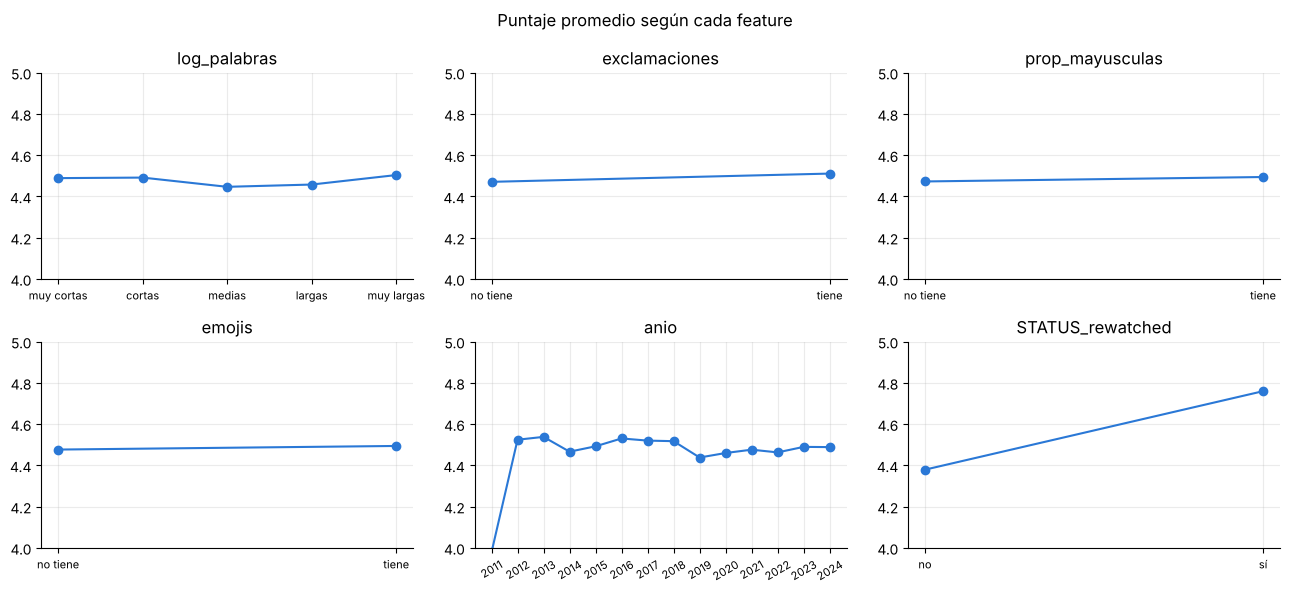

In [ ]:
# Puntaje promedio según cada feature (dividida en grupos)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, ['log_palabras', 'exclamaciones', 'prop_mayusculas', 'emojis', 'anio', 'STATUS_rewatched']):
    if col == 'log_palabras':
        # dividimos en 5 grupos con la misma cantidad de reseñas (quintiles)
        grupos = pd.qcut(F[col], 5, labels=['muy cortas', 'cortas', 'medias', 'largas', 'muy largas'])
    elif col in ['exclamaciones', 'prop_mayusculas', 'emojis']:
        # la mayoría de las reseñas tiene 0, así que comparamos "tiene" vs "no tiene"
        grupos = np.where(F[col] > 0, 'tiene', 'no tiene')
    elif col == 'STATUS_rewatched':
        grupos = F[col].map({0: 'no', 1: 'sí'})
    else:
        grupos = F[col]
    medias = data['y'].groupby(grupos, observed=True).mean()
    ax.plot(range(len(medias)), medias.values, marker='o', color=AZUL)
    ax.set_xticks(range(len(medias)), [str(g) for g in medias.index], rotation=30 if col == 'anio' else 0, fontsize=8)
    ax.set_title(col); ax.set_ylim(4, 5)
plt.suptitle('Puntaje promedio según cada feature')
plt.tight_layout(); plt.show()

Solo `STATUS_rewatched` muestra una diferencia clara en el puntaje promedio. (El punto de 2011 sale más bajo porque ahí quedaron agrupadas las pocas fechas viejas o erróneas que limitamos en la sección 4.2.) En las demás, el promedio se mueve muy poco. De todas formas, podrían ayudar combinadas con el texto, así que lo probamos.

### 8.1 Cómo combinarlas con el texto y por qué escalar

- El texto vectorizado es una matriz **dispersa** (casi todos ceros) con valores entre 0 y 1. Las features nuevas están en escalas muy distintas: el año vale ~2020 y las exclamaciones ~0.2.
- **Hay que escalarlas** (clase 3). Si no, el modelo trataría distinto a una feature solo por su escala, y la regularización de Ridge o de la Regresión Logística depende del tamaño de los coeficientes.
- Usamos **`StandardScaler`** (estandarización). Lo ajustamos **solo con el train** y después lo aplicamos a validación y test, para no usar información del test.
- Juntamos todo con `hstack` (pegar columnas una al lado de la otra).

In [ ]:
vectorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X_texto_exp = vectorizador.fit_transform(texto_exp)
X_texto_val = vectorizador.transform(texto_val)

def agregar_features(columnas):
    if not columnas:
        return X_texto_exp, X_texto_val
    escalador = StandardScaler().fit(F.iloc[idx_exp][columnas])
    A = hstack([X_texto_exp, csr_matrix(escalador.transform(F.iloc[idx_exp][columnas]))]).tocsr()
    B = hstack([X_texto_val, csr_matrix(escalador.transform(F.iloc[idx_val][columnas]))]).tocsr()
    return A, B

ESTILO = ['log_caracteres', 'log_palabras', 'log_oraciones', 'exclamaciones', 'preguntas', 'prop_mayusculas', 'emojis']
STATUS = ['STATUS_rewatched', 'STATUS_desconocido']

resultados_feat = {}
for nombre, columnas in [('solo texto', []), ('texto + estilo', ESTILO), ('texto + año', ['anio']),
                         ('texto + status', STATUS), ('texto + todas', ESTILO + ['anio'] + STATUS)]:
    A, B = agregar_features(columnas)
    pred = redondear(Ridge(alpha=1.0).fit(A, y_exp).predict(B))
    resultados_feat[nombre] = metricas(y_val, pred)
pd.DataFrame(resultados_feat).T.round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro
solo texto,0.4160,0.6210,0.3739,0.8679,0.9650,0.1517
texto + estilo,0.4161,0.6208,0.3730,0.8682,0.9654,0.1510
texto + año,0.4164,0.6221,0.3740,0.8675,0.9649,0.1518
texto + status,0.4028,0.6112,0.3952,0.8697,0.9674,0.1630
texto + todas,0.4025,0.6105,0.3949,0.8702,0.9676,0.1623


**Qué vemos** _(ver tabla)_:
- **`Status` es la que más ayuda**: baja el MAE de forma clara. Coincide con lo que vimos en el análisis.
- Las de **estilo** (longitud, "!", mayúsculas, emojis) y el **año** prácticamente no cambian nada. El texto ya tiene esa información: si alguien escribe "MASTERPIECE!!!", la palabra "masterpiece" ya dice que le gustó.

**✅ Decisión:** nos quedamos con **texto + `Status`**. Las otras features no mejoran y hacen el modelo más complejo sin necesidad (clase 4: features irrelevantes).

In [ ]:
COLUMNAS = STATUS
X_exp, X_val = agregar_features(COLUMNAS)
k_exp = (y_exp * 2).astype(int)    # para clasificar usamos clases enteras: 1 = 0.5★ ... 10 = 5★
print('Matriz de entrenamiento:', X_exp.shape)

Matriz de entrenamiento: (30000, 149343)


## 9. Modelado

### 9.1 Qué métrica usamos

| Métrica | Problema en este dataset |
|---|---|
| Accuracy | Predecir siempre 5★ ya da 47%. Además cuenta igual errar por media estrella que por cuatro |
| Accuracy con tolerancia ±0.5★ | Predecir siempre 4.5★ ya acierta casi el 90%, porque casi todo está entre 4 y 5 |
| F1-macro | Le da el mismo peso a todas las clases (sirve para ver si el modelo predice las clases raras), pero no tiene en cuenta el orden |
| **MAE** | Error promedio en estrellas. Tiene en cuenta el orden: errar por 0.5 pesa poco y errar por 4 pesa mucho |
| RMSE | Como el MAE, pero castiga más los errores grandes |

**✅ Decisión:** la métrica principal es el **MAE** (clase 5). Respeta que el target es ordinal y se entiende fácil: "en promedio el modelo se equivoca por X estrellas". Como el MAE se puede mejorar prediciendo siempre valores altos, también miramos el **F1-macro** y la **matriz de confusión**, para ver si el modelo realmente distingue puntajes.

### 9.2 Baselines

Todo lo que entrenemos tiene que ser mejor que:
- **Siempre la clase mayoritaria (5★).**
- **Siempre la mediana (4.5★):** es el valor fijo que da el menor MAE posible.

In [ ]:
resultados = {}
resultados['Baseline: siempre 5★'] = metricas(y_val, np.full(len(y_val), 5.0))
resultados['Baseline: siempre 4.5★'] = metricas(y_val, np.full(len(y_val), 4.5))
pd.DataFrame(resultados).T.round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro
Baseline: siempre 5★,0.5224,0.8832,0.4748,0.7179,0.8917,0.0644
Baseline: siempre 4.5★,0.4972,0.7125,0.2431,0.8917,0.9427,0.0391


Sin aprender nada, "siempre 5★" tiene 47% de accuracy y "siempre 4.5★" acierta el ~89% con tolerancia de media estrella. Por eso no usamos esas métricas para elegir el modelo.

### 9.3 Dos formas de plantear el problema

- **Clasificación multiclase:** cada valor de estrellas es una clase (10 clases). El modelo elige una. No sabe que 4.5 está cerca de 5: para él son categorías distintas.
- **Regresión:** el modelo predice un número (por ejemplo 4.3) y lo redondeamos a la media estrella más cercana (4.5). Así el modelo sí sabe que los puntajes tienen un orden y una distancia.

Probamos varios modelos de cada tipo y, para cada uno, distintos valores de su hiperparámetro principal.

In [ ]:
def guardar(nombre, pred, segundos):
    resultados[nombre] = {**metricas(y_val, pred), 'segundos': round(segundos, 1)}

# ---------- REGRESIÓN ----------
# Ridge: alpha controla la regularización (más alto = modelo más simple)
curva_ridge = {}
for alpha in [0.1, 0.3, 1, 3, 10, 30]:
    t = time.time()
    m = Ridge(alpha=alpha).fit(X_exp, y_exp)
    guardar(f'Regresión - Ridge alpha={alpha}', redondear(m.predict(X_val)), time.time() - t)
    curva_ridge[alpha] = {'train': mean_absolute_error(y_exp, redondear(m.predict(X_exp))),
                          'validación': mean_absolute_error(y_val, redondear(m.predict(X_val)))}

# ---------- CLASIFICACIÓN ----------
# Naive Bayes: alpha es el suavizado. Usa solo el texto (no acepta valores negativos como los de StandardScaler)
for alpha in [0.01, 0.1, 1]:
    t = time.time()
    m = MultinomialNB(alpha=alpha).fit(X_texto_exp, k_exp)
    guardar(f'Clasificación - Naive Bayes alpha={alpha}', m.predict(X_texto_val) / 2, time.time() - t)

# Regresión Logística: C es la inversa de la regularización (más alto = menos regularización)
for C in [0.5, 2, 8]:
    t = time.time()
    m = LogisticRegression(C=C, solver='saga', max_iter=100, tol=1e-3).fit(X_exp, k_exp)
    guardar(f'Clasificación - Regresión Logística C={C}', m.predict(X_val) / 2, time.time() - t)

# SVM lineal
for C in [0.03, 0.1, 0.3]:
    t = time.time()
    m = LinearSVC(C=C).fit(X_exp, k_exp)
    guardar(f'Clasificación - SVM lineal C={C}', m.predict(X_val) / 2, time.time() - t)

pd.DataFrame(resultados).T.sort_values('MAE').round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro,segundos
Regresión - Ridge alpha=1,0.4028,0.6112,0.3952,0.8697,0.9674,0.1630,1.7
Regresión - Ridge alpha=3,0.4056,0.6162,0.3812,0.8841,0.9664,0.1357,1.0
Clasificación - Regresión Logística C=8,0.4138,0.7141,0.4907,0.8083,0.9443,0.1569,28.6
Regresión - Ridge alpha=0.3,0.4166,0.6275,0.3949,0.8456,0.9629,0.1679,2.9
Clasificación - Regresión Logística C=2,0.4166,0.7302,0.4990,0.8060,0.9407,0.1371,19.2
Regresión - Ridge alpha=10,0.4180,0.6331,0.3616,0.8887,0.9626,0.1138,0.6
Clasificación - SVM lineal C=0.3,0.4202,0.7348,0.4980,0.8026,0.9385,0.1420,35.3
Regresión - Ridge alpha=30,0.4308,0.6512,0.3425,0.8944,0.9565,0.0958,0.5
Regresión - Ridge alpha=0.1,0.4342,0.6493,0.3923,0.8195,0.9565,0.1708,4.7
Clasificación - SVM lineal C=0.1,0.4368,0.7682,0.5000,0.7886,0.9300,0.1148,18.4


### 9.4 Curva de validación de Ridge (complejidad del modelo)

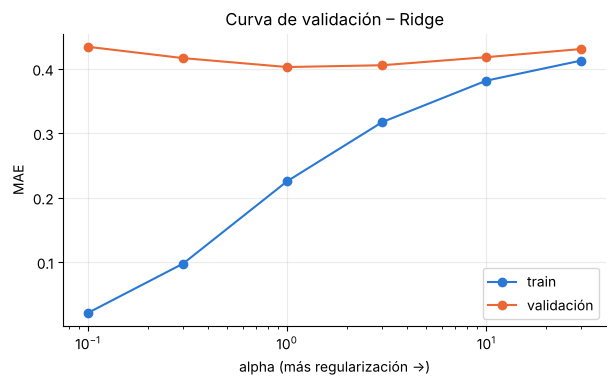

In [ ]:
curva = pd.DataFrame(curva_ridge).T
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curva.index, curva['train'], marker='o', color=AZUL, label='train')
ax.plot(curva.index, curva['validación'], marker='o', color=NARANJA, label='validación')
ax.set_xscale('log'); ax.set_xlabel('alpha (más regularización →)'); ax.set_ylabel('MAE')
ax.set_title('Curva de validación – Ridge'); ax.legend()
plt.show()

Como vimos en clase (bias vs. variance):
- Con **`alpha` chico**, el error en train es casi 0 pero en validación es más alto: **overfitting**. Con tantas features (~250.000) el modelo puede "memorizar" las reseñas.
- Con **`alpha` grande**, los dos errores suben: **underfitting**. El modelo queda demasiado simple y predice todo cerca del promedio.
- El mejor punto está alrededor de **`alpha = 1`**.

### 9.5 Árboles de decisión y Random Forest

Los árboles son lentos con 250.000 columnas. Para poder probarlos usamos las **5.000 palabras más frecuentes** (`max_features=5000`) y **15.000 reseñas**. Para que la comparación sea justa, entrenamos también un Ridge con esos mismos datos.

In [ ]:
n = 15_000
vec_chico = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=5000, sublinear_tf=True)
Xc_exp = vec_chico.fit_transform(texto_exp[:n])
Xc_val = vec_chico.transform(texto_val)

for prof in [10, 30, None]:
    t = time.time()
    m = DecisionTreeRegressor(max_depth=prof, min_samples_leaf=20, random_state=SEED).fit(Xc_exp, y_exp[:n])
    guardar(f'Regresión - Árbol max_depth={prof}', redondear(m.predict(Xc_val)), time.time() - t)
    t = time.time()
    m = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, random_state=SEED).fit(Xc_exp, k_exp[:n])
    guardar(f'Clasificación - Árbol max_depth={prof}', m.predict(Xc_val) / 2, time.time() - t)

t = time.time()
m = RandomForestRegressor(n_estimators=100, max_features='sqrt', min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(Xc_exp, y_exp[:n])
guardar('Regresión - Random Forest (100 árboles)', redondear(m.predict(Xc_val)), time.time() - t)
t = time.time()
m = RandomForestClassifier(n_estimators=100, max_features='sqrt', min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(Xc_exp, k_exp[:n])
guardar('Clasificación - Random Forest (100 árboles)', m.predict(Xc_val) / 2, time.time() - t)

t = time.time()
m = Ridge(alpha=1.0).fit(Xc_exp, y_exp[:n])
guardar('Regresión - Ridge (mismos datos que los árboles)', redondear(m.predict(Xc_val)), time.time() - t)

pd.DataFrame(resultados).T.loc[lambda d: d.index.str.contains('Árbol|Forest|mismos')].round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro,segundos
Regresión - Árbol max_depth=10,0.4845,0.7229,0.3196,0.8396,0.9408,0.0991,2.0
Clasificación - Árbol max_depth=10,0.5149,0.8524,0.4516,0.7274,0.9051,0.0890,2.3
Regresión - Árbol max_depth=30,0.4995,0.7330,0.3063,0.8255,0.9369,0.1044,4.7
Clasificación - Árbol max_depth=30,0.5049,0.8212,0.4272,0.7492,0.9148,0.1070,5.2
Regresión - Árbol max_depth=None,0.5115,0.7540,0.3279,0.7827,0.9352,0.1146,7.0
Clasificación - Árbol max_depth=None,0.5016,0.7987,0.4035,0.7606,0.9238,0.1160,7.5
Regresión - Random Forest (100 árboles),0.4756,0.6831,0.2687,0.8890,0.9512,0.0666,16.7
Clasificación - Random Forest (100 árboles),0.5055,0.8614,0.4772,0.7337,0.9004,0.0770,15.0
Regresión - Ridge (mismos datos que los árboles),0.4536,0.6638,0.3475,0.8306,0.9588,0.1344,0.1


Aun con los mismos datos, **Ridge le gana a los árboles y al Random Forest**. En el texto, cada palabra aporta un poquito al puntaje y un modelo lineal suma todos esos aportes. Un árbol, en cambio, va decidiendo de a una palabra por vez. El **Random Forest de clasificación** además termina prediciendo casi siempre 5★, porque es la clase que más aparece en las hojas.

### 9.6 ¿Por qué no usamos SVM con kernel?

En clase vimos que el SVM con kernel necesita comparar **todos los pares de reseñas**, así que el tiempo crece mucho con la cantidad de datos. Lo medimos entrenando con 1.000, 2.000 y 4.000 reseñas:

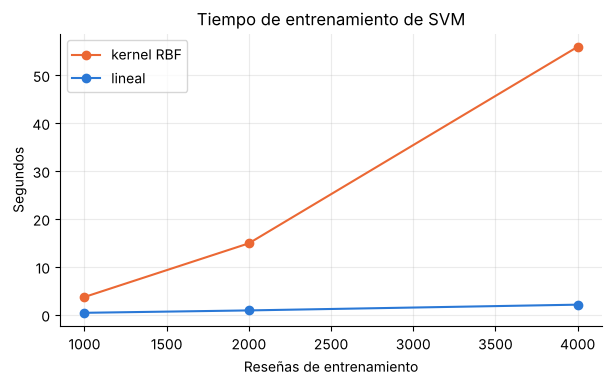

,SVM kernel RBF (seg),SVM lineal (seg)
1000,3.7,0.4
2000,14.9,0.9
4000,55.9,2.1


In [ ]:
tiempos = {}
for cantidad in [1000, 2000, 4000]:
    t = time.time(); SVC(kernel='rbf').fit(X_exp[:cantidad], k_exp[:cantidad]); t_rbf = time.time() - t
    t = time.time(); LinearSVC(C=0.3).fit(X_exp[:cantidad], k_exp[:cantidad]); t_lineal = time.time() - t
    tiempos[cantidad] = {'SVM kernel RBF (seg)': round(t_rbf, 1), 'SVM lineal (seg)': round(t_lineal, 1)}
tiempos = pd.DataFrame(tiempos).T

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tiempos.index, tiempos['SVM kernel RBF (seg)'], marker='o', color=NARANJA, label='kernel RBF')
ax.plot(tiempos.index, tiempos['SVM lineal (seg)'], marker='o', color=AZUL, label='lineal')
ax.set_xlabel('Reseñas de entrenamiento'); ax.set_ylabel('Segundos'); ax.set_title('Tiempo de entrenamiento de SVM')
ax.legend(); plt.show()
tiempos

Cada vez que duplicamos la cantidad de reseñas, el SVM con kernel RBF tarda **unas 4 veces más** (crece aproximadamente con el cuadrado de los datos). Con las 70.000 reseñas tardaría horas para cada combinación de hiperparámetros. El SVM lineal tarda menos de un segundo.

Siguiendo lo que vimos en clase ("primero probar el kernel lineal"), usamos solo SVM lineal. Además, con tantas columnas los datos ya son casi separables de forma lineal.

### 9.7 Comparación de todos los modelos

In [ ]:
tabla_final = pd.DataFrame(resultados).T.sort_values('MAE')
tabla_final.round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro,segundos
Regresión - Ridge alpha=1,0.4028,0.6112,0.3952,0.8697,0.9674,0.1630,1.7
Regresión - Ridge alpha=3,0.4056,0.6162,0.3812,0.8841,0.9664,0.1357,1.0
Clasificación - Regresión Logística C=8,0.4138,0.7141,0.4907,0.8083,0.9443,0.1569,28.6
Regresión - Ridge alpha=0.3,0.4166,0.6275,0.3949,0.8456,0.9629,0.1679,2.9
Clasificación - Regresión Logística C=2,0.4166,0.7302,0.4990,0.8060,0.9407,0.1371,19.2
Regresión - Ridge alpha=10,0.4180,0.6331,0.3616,0.8887,0.9626,0.1138,0.6
Clasificación - SVM lineal C=0.3,0.4202,0.7348,0.4980,0.8026,0.9385,0.1420,35.3
Regresión - Ridge alpha=30,0.4308,0.6512,0.3425,0.8944,0.9565,0.0958,0.5
Regresión - Ridge alpha=0.1,0.4342,0.6493,0.3923,0.8195,0.9565,0.1708,4.7
Clasificación - SVM lineal C=0.1,0.4368,0.7682,0.5000,0.7886,0.9300,0.1148,18.4


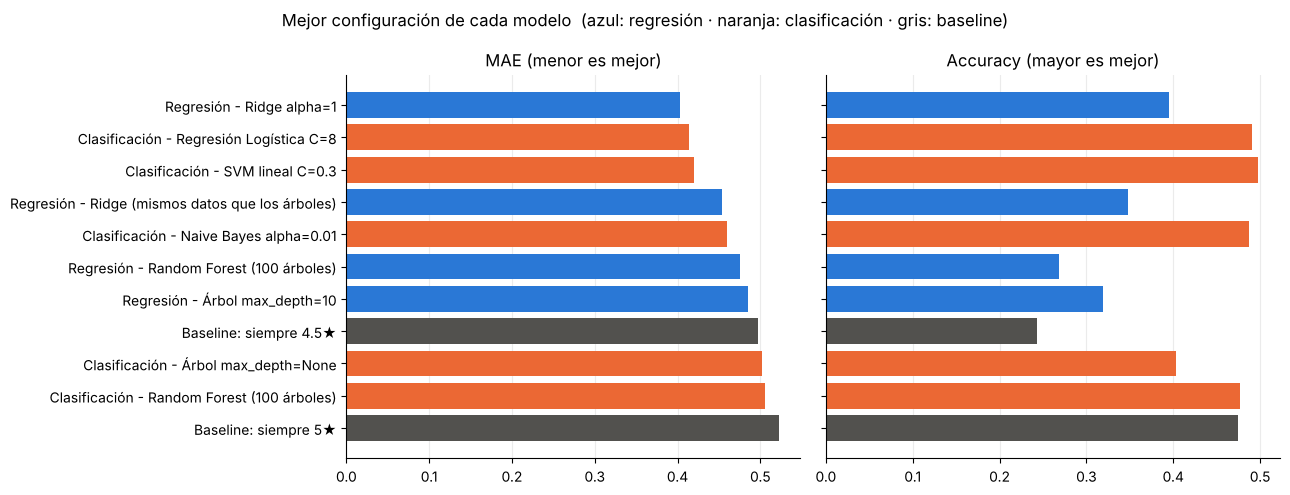

In [ ]:
# Mejor configuración de cada modelo
familia = tabla_final.index.str.replace(r'\s(alpha|C|max_depth)=\S+', '', regex=True)
mejores = tabla_final.assign(familia=familia).groupby('familia', sort=False).head(1).drop(columns='familia')
mejores = mejores.sort_values('MAE', ascending=False)
colores = [GRIS if 'Baseline' in i else (AZUL if i.startswith('Regresión') else NARANJA) for i in mejores.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(mejores.index, mejores['MAE'], color=colores); axes[0].set_title('MAE (menor es mejor)')
axes[1].barh(mejores.index, mejores['Accuracy'], color=colores); axes[1].set_title('Accuracy (mayor es mejor)')
for ax in axes:
    ax.grid(axis='y', visible=False)
plt.suptitle('Mejor configuración de cada modelo  (azul: regresión · naranja: clasificación · gris: baseline)')
plt.tight_layout(); plt.show()

### 9.8 ¿Clasificación o regresión?

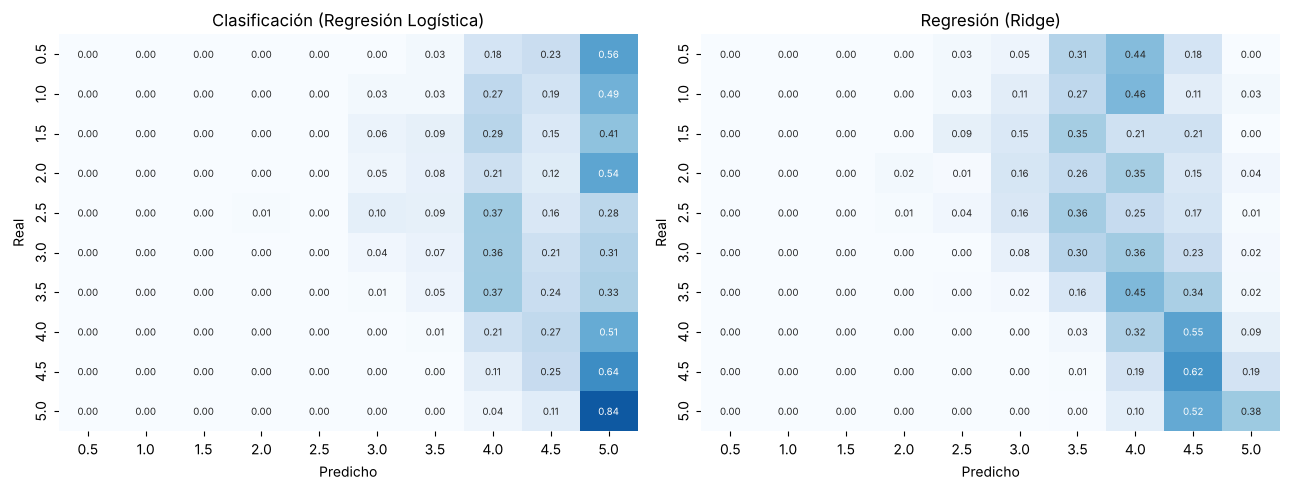

Puntajes que predice cada modelo (validación):


,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
real,39,37,34,85,103,275,510,1738,2431,4748
Logística,0,0,0,2,0,34,92,1202,1846,6824
Ridge,0,0,0,3,12,80,359,1905,5225,2416


In [ ]:
# Comparamos las matrices de confusión del mejor modelo de cada tipo (en validación)
ridge = Ridge(alpha=1.0).fit(X_exp, y_exp)
logistica = LogisticRegression(C=2, solver='saga', max_iter=100, tol=1e-3).fit(X_exp, k_exp)
pred_ridge = redondear(ridge.predict(X_val))
pred_log = logistica.predict(X_val) / 2

estrellas = np.arange(1, 11) / 2
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, titulo in [(axes[0], pred_log, 'Clasificación (Regresión Logística)'), (axes[1], pred_ridge, 'Regresión (Ridge)')]:
    cm = confusion_matrix((y_val * 2).astype(int), (pred * 2).astype(int), labels=np.arange(1, 11))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax,
                xticklabels=estrellas, yticklabels=estrellas, vmin=0, vmax=1, annot_kws={'fontsize': 7})
    ax.set_title(titulo); ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

print('Puntajes que predice cada modelo (validación):')
pd.DataFrame({'real': pd.Series(y_val).value_counts(), 'Logística': pd.Series(pred_log).value_counts(),
              'Ridge': pd.Series(pred_ridge).value_counts()}).reindex(estrellas).fillna(0).astype(int).T

**Análisis** _(ver tabla de resultados y matrices)_:
- La **clasificación** (Regresión Logística, SVM lineal) tiene el **mejor accuracy** (~50%), pero lo logra prediciendo casi solo 4.5★ y 5★. Cuando se equivoca, a veces se equivoca por mucho, porque para ella todas las clases son "igual de distintas".
- La **regresión** (Ridge) tiene **menos accuracy** pero **mejor MAE y RMSE**: sus errores suelen ser de media estrella o una estrella. Como predice un número, "sabe" que 4 está entre 3.5 y 4.5. Además predice **más variedad de puntajes** (no solo 4.5 y 5). Como contra, predice muchas menos 5★ de las que hay realmente: la regresión "tira" las predicciones hacia el promedio (4.48), y muchas reseñas de 5★ terminan en 4.5★.
- Naive Bayes es el más rápido (menos de 1 segundo) pero es peor. Con `alpha` alto predice casi siempre 5★.
- Los árboles y el Random Forest quedaron por detrás de los modelos lineales.

**¿Cuál funciona mejor y por qué?** Para este problema, **la regresión**. El puntaje es **ordinal**, y la regresión usa ese orden: equivocarse por poco le cuesta poco y equivocarse por mucho le cuesta mucho. La clasificación solo gana en accuracy exacto, que como vimos es la métrica menos útil acá.

**✅ Decisión: el modelo final es Ridge (`alpha=1`) con texto TF-IDF + `Status`, redondeando a la media estrella más cercana.** Es el de menor MAE, es rápido (se entrena en segundos) y se puede interpretar (podemos ver qué palabras suben o bajan el puntaje).

### 9.9 ¿Más datos ayudan? (curva de aprendizaje)

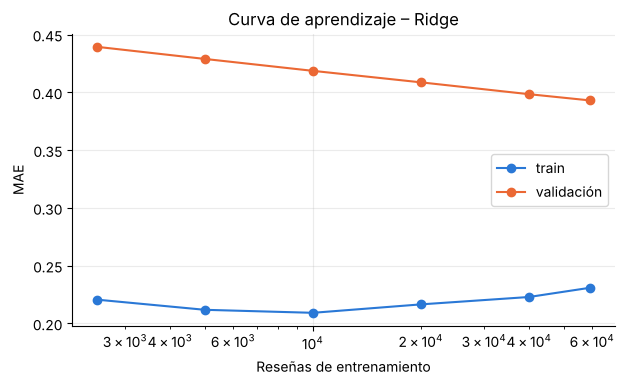

,train,validación
2500,0.2206,0.4394
5000,0.2118,0.4289
10000,0.2092,0.4186
20000,0.2165,0.4086
40000,0.2229,0.3984
59203,0.2309,0.3930


In [ ]:
idx_sin_val = np.setdiff1d(idx_train, idx_val)
vec_lc = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
esc_lc = StandardScaler().fit(F.iloc[idx_sin_val][COLUMNAS])
X_lc = hstack([vec_lc.fit_transform(data['texto'].values[idx_sin_val]),
               csr_matrix(esc_lc.transform(F.iloc[idx_sin_val][COLUMNAS]))]).tocsr()
X_lc_val = hstack([vec_lc.transform(texto_val), csr_matrix(esc_lc.transform(F.iloc[idx_val][COLUMNAS]))]).tocsr()

curva_ap = {}
orden = np.random.RandomState(SEED).permutation(len(idx_sin_val))
for cantidad in [2_500, 5_000, 10_000, 20_000, 40_000, len(idx_sin_val)]:
    s = orden[:cantidad]
    m = Ridge(alpha=1.0).fit(X_lc[s], y[idx_sin_val][s])
    curva_ap[cantidad] = {'train': mean_absolute_error(y[idx_sin_val][s], redondear(m.predict(X_lc[s]))),
                          'validación': mean_absolute_error(y_val, redondear(m.predict(X_lc_val)))}
curva_ap = pd.DataFrame(curva_ap).T
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curva_ap.index, curva_ap['train'], marker='o', color=AZUL, label='train')
ax.plot(curva_ap.index, curva_ap['validación'], marker='o', color=NARANJA, label='validación')
ax.set_xscale('log'); ax.set_xlabel('Reseñas de entrenamiento'); ax.set_ylabel('MAE')
ax.set_title('Curva de aprendizaje – Ridge'); ax.legend()
plt.show()
curva_ap.round(4)

El error en validación **sigue bajando** a medida que agregamos reseñas. Por eso el modelo final lo entrenamos con **todo el train** (no solo con la muestra de exploración).

## 10. Evaluación final en test

Entrenamos el modelo elegido con **todo el train** y lo evaluamos **una sola vez** en test.

In [ ]:
vec_final = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
esc_final = StandardScaler().fit(F.iloc[idx_train][COLUMNAS])

def armar_X(textos, features, ajustar=False):
    X_txt = vec_final.fit_transform(textos) if ajustar else vec_final.transform(textos)
    return hstack([X_txt, csr_matrix(esc_final.transform(features[COLUMNAS]))]).tocsr()

X_train = armar_X(data['texto'].values[idx_train], F.iloc[idx_train], ajustar=True)
X_test = armar_X(data['texto'].values[idx_test], F.iloc[idx_test])
y_train, y_test = y[idx_train], y[idx_test]

modelo_final = Ridge(alpha=1.0).fit(X_train, y_train)
pred_test = redondear(modelo_final.predict(X_test))

pd.DataFrame({'Baseline siempre 5★': metricas(y_test, np.full(len(y_test), 5.0)),
              'Baseline siempre 4.5★': metricas(y_test, np.full(len(y_test), 4.5)),
              'Modelo final (Ridge)': metricas(y_test, pred_test)}).T.round(4)

,MAE,RMSE,Accuracy,Acc ±0.5,Acc ±1,F1-macro
Baseline siempre 5★,0.5224,0.8835,0.4749,0.7179,0.8917,0.0644
Baseline siempre 4.5★,0.4973,0.7129,0.2430,0.8917,0.9427,0.0391
Modelo final (Ridge),0.3946,0.6023,0.4038,0.8744,0.9685,0.1743


Los resultados en test son **parecidos a los de validación**, así que no nos "sobreajustamos" a la validación mientras elegíamos.

Frente al mejor baseline (siempre 4.5★), el modelo **baja el MAE y el RMSE** y tiene un **F1-macro mucho mayor**, porque sí predice distintos puntajes. La mejora en MAE parece chica, pero hay que tener en cuenta que el 70% de las reseñas son de 4.5★ o 5★: la diferencia entre "me encantó" (4.5) y "me encantó" (5) es muy difícil de ver solo con el texto.

### 10.1 Matriz de confusión

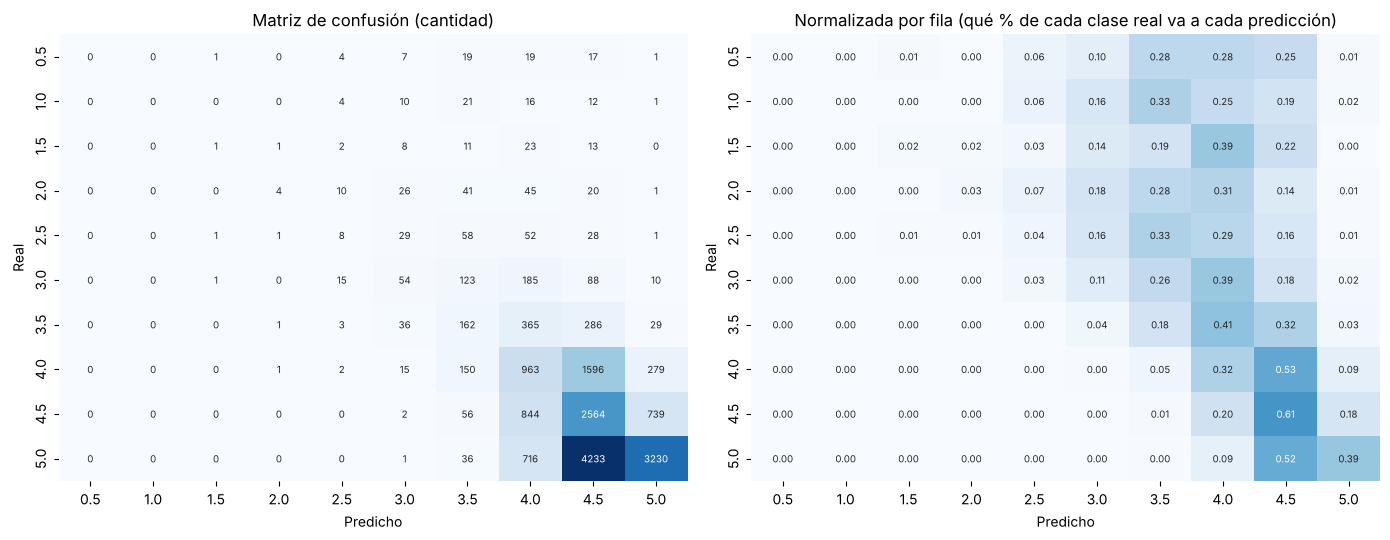

Clases que el modelo nunca predice: [0.5, 1.0]


,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
reales,68,64,59,147,178,476,882,3006,4205,8216
predichas,0,0,4,8,48,188,677,3228,8857,4291


In [ ]:
cm = confusion_matrix((y_test * 2).astype(int), (pred_test * 2).astype(int), labels=np.arange(1, 11))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=estrellas, yticklabels=estrellas, annot_kws={'fontsize': 7})
axes[0].set_title('Matriz de confusión (cantidad)')
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=estrellas, yticklabels=estrellas, vmin=0, vmax=1, annot_kws={'fontsize': 7})
axes[1].set_title('Normalizada por fila (qué % de cada clase real va a cada predicción)')
for ax in axes:
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

predichas = pd.Series(pred_test).value_counts().reindex(estrellas, fill_value=0)
print('Clases que el modelo nunca predice:', list(predichas[predichas == 0].index))
pd.DataFrame({'reales': pd.Series(y_test).value_counts().reindex(estrellas), 'predichas': predichas}).T

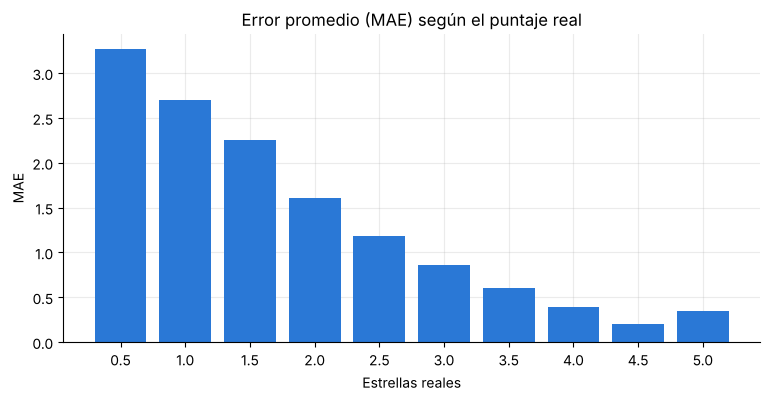

In [ ]:
error_por_clase = pd.DataFrame({'real': y_test, 'error': np.abs(y_test - pred_test)}).groupby('real')['error'].mean()
fig, ax = plt.subplots()
ax.bar(error_por_clase.index.astype(str), error_por_clase.values, color=AZUL)
ax.set_title('Error promedio (MAE) según el puntaje real'); ax.set_xlabel('Estrellas reales'); ax.set_ylabel('MAE')
plt.show()

**Análisis:**
- **Los errores están cerca de la diagonal**: cuando el modelo se equivoca, casi siempre es por media estrella o una estrella. Errores grandes hay pocos.
- **La mayor confusión está entre 4, 4.5 y 5★**: el texto de una reseña de 4.5★ y una de 5★ suele ser muy parecido.
- **Las clases bajas (0.5★ a 2★) casi nunca se predicen.** Las reseñas de 1★ el modelo las pone más abajo que las positivas (las ordena bien), pero no llega tan abajo. Es consecuencia del **desbalance**: con solo ~3% de reseñas en esas clases, el modelo aprende que casi nunca conviene predecir un puntaje tan bajo. Por eso el error es muy alto para las clases bajas y muy bajo para 4.5 y 5★.
- Una regresión también tiende a predecir valores "hacia el promedio" y le cuesta llegar a los extremos.

### 10.2 ¿Cómo le va según el idioma y la longitud?

In [ ]:
resultado_test = data.iloc[idx_test].assign(pred=pred_test, error=np.abs(y_test - pred_test))
resultado_test['largo'] = pd.cut(resultado_test['Review'].str.split().str.len(), [0, 5, 20, 100, 500, 100_000],
                                 labels=['1-5 palabras', '6-20', '21-100', '101-500', 'más de 500'])

def comparar(g):
    return pd.Series({'reseñas': len(g), 'MAE modelo': g['error'].mean(), 'MAE siempre 4.5★': np.abs(g['y'] - 4.5).mean()})

print('Según idioma:')
print(resultado_test.groupby('idioma').apply(comparar).round(3))
print('\nSegún longitud:')
print(resultado_test.groupby('largo', observed=True).apply(comparar).round(3))

Según idioma:
             reseñas  MAE modelo  MAE siempre 4.5★
idioma                                            
inglés       15489.0       0.390             0.499
muy corta      547.0       0.495             0.559
otro idioma   1265.0       0.404             0.453

Según longitud:
              reseñas  MAE modelo  MAE siempre 4.5★
largo                                              
1-5 palabras    781.0       0.503             0.555
6-20           3271.0       0.448             0.482
21-100         5402.0       0.393             0.497
101-500        6550.0       0.365             0.498
más de 500     1297.0       0.350             0.500


- En **otros idiomas** el modelo también le gana al baseline, pero mejora bastante menos que en inglés (baja el error unas 0.05 estrellas, contra 0.11 en inglés): hay pocas reseñas de cada idioma para aprender su vocabulario.
- Las reseñas **muy cortas** son las más difíciles (con "wow" o "what" no hay mucho de dónde sacar). Igual el modelo les gana al baseline, así que hicimos bien en no borrarlas.

### 10.3 ¿Qué palabras usa el modelo?

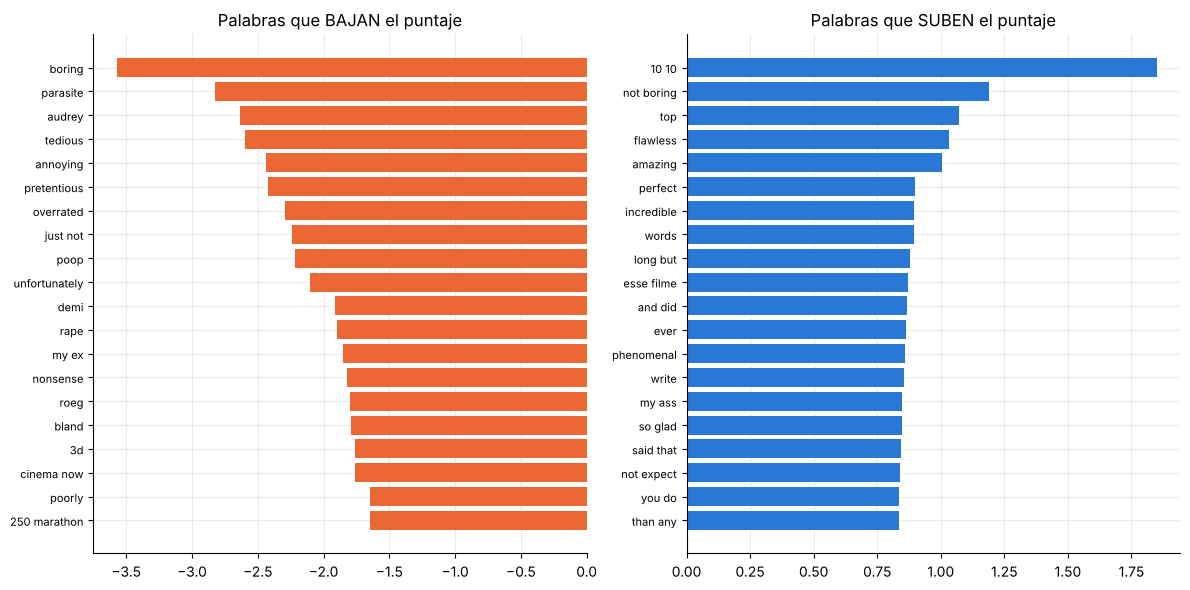

Coeficientes de Status:
STATUS_rewatched      0.1252
STATUS_desconocido   -0.0030
dtype: float64

Top 15 que bajan: ['boring', 'parasite', 'audrey', 'tedious', 'annoying', 'pretentious', 'overrated', 'just not', 'poop', 'unfortunately', 'demi', 'rape', 'my ex', 'nonsense', 'roeg']
Top 15 que suben: ['10 10', 'not boring', 'top', 'flawless', 'amazing', 'perfect', 'incredible', 'words', 'long but', 'esse filme', 'and did', 'ever', 'phenomenal', 'write', 'my ass']


In [ ]:
nombres = list(vec_final.get_feature_names_out()) + COLUMNAS
coeficientes = pd.Series(modelo_final.coef_, index=nombres)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
bajan = coeficientes.nsmallest(20).sort_values(ascending=False)
suben = coeficientes.nlargest(20).sort_values()
axes[0].barh(bajan.index, bajan.values, color=NARANJA); axes[0].set_title('Palabras que BAJAN el puntaje')
axes[1].barh(suben.index, suben.values, color=AZUL); axes[1].set_title('Palabras que SUBEN el puntaje')
for ax in axes:
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Coeficientes de Status:'); print(coeficientes[COLUMNAS].round(4))
print('\nTop 15 que bajan:', list(coeficientes.nsmallest(15).index))
print('Top 15 que suben:', list(coeficientes.nlargest(15).index))

**Qué vemos** _(ver gráfico y listas)_:
- La mayoría son **palabras de opinión**: *boring, tedious, pretentious, overrated, unfortunately* bajan el puntaje; *flawless, perfect, amazing, phenomenal* lo suben.
- Aparecen **bigramas** que solo existen porque no sacamos stopwords y usamos `ngram_range=(1,2)`: *"not boring"* sube el puntaje (¡al revés que "boring"!) y *"just not"* lo baja. Esto confirma la decisión de la sección 7.
- *"10 10"* es la nota "10/10" escrita en la reseña: el modelo aprendió solo a usarla.
- *"esse filme"* (portugués): aprendió algo de otros idiomas, aunque poco.
- **Hallazgo importante: también aparecen nombres propios** que bajan el puntaje: *parasite*, *demi* (Demi Moore), *audrey* (Audrey Hepburn) y *roeg* (el director Nicolas Roeg). Son nombres de las películas con promedio más bajo (la *Parasite* de 1982 con Demi Moore, *War and Peace* con Audrey Hepburn y *Eureka* de Roeg, ver sección 4.1). El modelo los usa como **pista de qué película es**, que es justo el riesgo que mencionamos en la sección 7.1. Con la división aleatoria esto "funciona", porque esas películas también están en test. Pero con una película nueva esas pistas no servirían. Una mejora sería sacar los nombres de actores, directores y títulos, o evaluar con una división por película.
- `STATUS_rewatched` tiene coeficiente positivo, como esperábamos.

### 10.4 Errores grandes: reseñas "inconsistentes"

Uno de los usos del enunciado es **detectar reseñas donde el texto no coincide con el puntaje**. Miramos dónde el modelo más se equivoca:

In [ ]:
resultado_test.sort_values('error', ascending=False)[['Review', 'y', 'pred', 'Movie']].head(12)

,Review,y,pred,Movie
82549,could this be one of the most devious films ever made?,0.5,5.0,whiplash-2014
58129,"a loving treatise to young womens asses, thighs, pussy, etc, so thank you hideki anno for making another based and kino masterpiece. not nearly as...",0.5,4.5,evangelion-3010-thrice-upon-a-time
28692,An absolute crime against cinema only the Weinsteins could pick this up and push this for oscars. The very definition of tasteless,0.5,4.5,life-is-beautiful
28528,Cinema was a mistake.,0.5,4.5,life-is-beautiful
3425,I thought it would be funny to give The Godfather half a star.,0.5,4.5,the-godfather
39432,It's my dogs birthday today I have no thoughts on the film but he's One,0.5,4.5,brief-encounter
5538,nothing compared to ice age,0.5,4.5,la-haine
33880,the real elephant was inside of us all along.,0.5,4.5,an-elephant-sitting-still
54203,Animals can't talk. Dumbass.,0.5,4.5,fantastic-mr-fox
38504,how is this on anne hathaways top 4??,0.5,4.5,all-that-jazz


En los errores más grandes aparecen:
- **Ironía y sarcasmo**, el problema principal del análisis de sentimiento (clase 6).
- **Reseñas que no hablan de la película** (chistes, memes): no hay forma de saber el puntaje por el texto.
- **Contradicciones reales**: reseñas que elogian la película pero tienen un puntaje muy bajo (o al revés). Estas son las que la plataforma querría revisar.

Una regla simple sería marcar para revisar las reseñas donde la predicción y el puntaje difieren en 2.5 estrellas o más:

In [ ]:
marcadas = np.abs(modelo_final.predict(X_test) - y_test) >= 2.5
print(f'Reseñas marcadas para revisar: {marcadas.sum()} de {len(y_test)} ({100 * marcadas.mean():.1f}%)')

Reseñas marcadas para revisar: 130 de 17301 (0.8%)


## 11. Completar las reseñas sin puntaje

Usamos el modelo final para predecir el puntaje de las reseñas que no tenían.

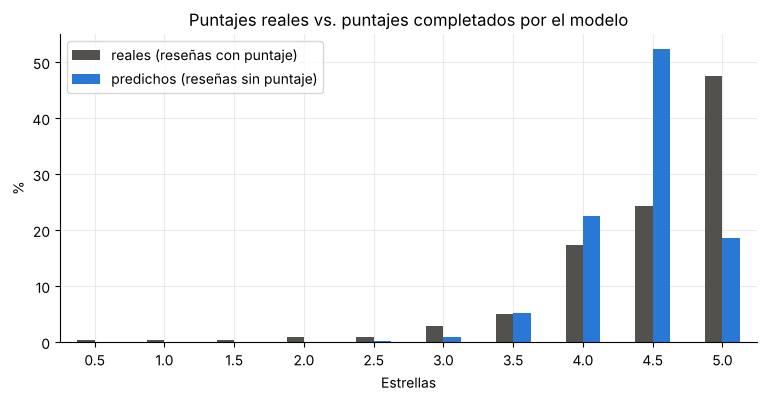

,Review,Status,puntaje_predicho
3150,I just had one long emotional flashback after another as I watched a child being brutalized over and over again.,Watched,4.0
315,"The crisp, neat way the prisoners remove the slats from the ground most every time they go down the hole is such a simple but effective image. It'...",Watched,4.5
2178,"**Part of the Best Picture Project**The perfect satire/black comedy. Shows the extremes of the subject without devolving into parody, features a c...",Watched,4.5
2772,i rly liked this as a kid and i rly like it now. hopefully the movie will follow suit. that lint dog raised this half a star. i adore that thing.,Rewatched,4.5
430,"Sometimes I struggle even just to see this work as ""significant"" and ""influential."" I know I am a colossal philistine but Tarkovsky is just not my...",Watched,3.5
2138,they just don't make movies with this much beeping anymore,Watched,4.5
2817,"This is a really annoying YouTube short but it has its audience. Thank god it's only 3 minutes long.Now if this was a 90-minute feature, ooof... I...",Desconocido,3.0
1667,"There is something to be said for a film that, when you’re at the end of your badly-fraying rope, can restore a little bit of faith that there is ...",Watched,4.5


In [ ]:
X_sin_puntaje = armar_X(sin_puntaje['texto'].values, F_sin_puntaje)
sin_puntaje['puntaje_predicho'] = redondear(modelo_final.predict(X_sin_puntaje))

comparacion = pd.DataFrame({
    'reales (reseñas con puntaje)': pd.Series(y).value_counts(normalize=True),
    'predichos (reseñas sin puntaje)': sin_puntaje['puntaje_predicho'].value_counts(normalize=True),
}).reindex(estrellas).fillna(0) * 100
comparacion.round(1).plot.bar(color=[GRIS, AZUL], figsize=(9, 4), rot=0)
plt.title('Puntajes reales vs. puntajes completados por el modelo'); plt.ylabel('%'); plt.xlabel('Estrellas')
plt.show()
sin_puntaje[['Review', 'Status', 'puntaje_predicho']].sample(8, random_state=SEED)

Las predicciones se concentran entre 4 y 5 estrellas y casi no aparecen puntajes bajos, por lo que vimos en la matriz de confusión. Estos puntajes sirven como **estimación** (por ejemplo, para calcular promedios), pero no reemplazan al puntaje real del usuario.

## 12. Conclusiones

**Sobre los datos**
- El target tiene **10 clases ordinales** y está **muy desbalanceado** (47% de 5★). Esto hace que el accuracy y las métricas con tolerancia engañen.
- Encontramos varios problemas: reseñas sin puntaje, cortadas, duplicadas, fechas en calendario budista y películas confundidas por tener el mismo nombre (`parasite`).
- Además del texto, lo que más sirve es **`Status`**: quien vuelve a ver una película la puntúa mejor.

**Sobre el preprocesamiento**
- **No conviene sacar stopwords** en reseñas, porque se pierden negaciones como "not good".
- Stemming y lematización no mejoraron.
- **TF-IDF con bigramas** fue la mejor representación. `min_df` controla mucho el tamaño del vocabulario.
- Las features de longitud, signos, mayúsculas, emojis y año no aportaron por encima del texto.

**Sobre los modelos**
- Plantear el problema como **regresión** funcionó mejor que como clasificación para el MAE, porque la regresión tiene en cuenta el orden de los puntajes. La clasificación solo gana en accuracy.
- El modelo aprende sobre todo **palabras de opinión**, pero también algunos **nombres propios** de las películas con promedio bajo (*parasite*, *demi*, *audrey*). Es una "pista" que no serviría con películas nuevas.
- Los **modelos lineales** (Ridge, Regresión Logística, SVM lineal) funcionaron mejor que los árboles para texto, y son mucho más rápidos. El **SVM con kernel** no es viable con tantos datos.
- El modelo final (Ridge) supera a los baselines. Sus errores son casi siempre de media estrella o una estrella, pero **casi no predice puntajes bajos** por el desbalance.

**Qué mejoraríamos en el futuro**
1. Probar **embeddings** o modelos pre-entrenados (clase 6) que entiendan mejor el contexto, la ironía y otros idiomas.
2. Atacar el **desbalance**: conseguir más reseñas con puntajes bajos o darle más peso a esas clases al entrenar.
3. Probar métodos pensados para **targets ordinales**, por ejemplo ajustar dónde redondeamos (en vez de cortar siempre en la mitad entre dos puntajes).
4. Sacar los nombres propios (actores, directores, títulos) del texto y evaluar con una división por película, para medir cómo funciona con películas que el modelo nunca vio.
5. Corregir los errores de scraping (películas con el mismo nombre y reseñas cortadas).
6. Si se usara en la plataforma: guardar el modelo, exponerlo como API y monitorear que los datos no cambien con el tiempo (clase 10).

## 13. Uso de IA generativa

_(Completar con lo que realmente hizo el grupo.)_

Usamos un asistente de IA (Claude, de Anthropic) para:
- Explorar alternativas de preprocesamiento, métricas y formas de dividir los datos.
- Escribir y corregir partes del código (funciones de limpieza, experimentos y gráficos).
- Ayudarnos a redactar las explicaciones y las conclusiones.

Las decisiones las tomamos mirando los resultados de cada experimento del notebook, y revisamos todo el código para poder explicarlo.